In [1]:
# import libraies
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import sqlite3 
import seaborn as sns 
from pathlib import Path

In [2]:
# create the default path
BASE_PATH = Path.cwd()

In [3]:
# connect to the sql database 
conn = sqlite3.connect(BASE_PATH / "../database" / 'safety.db')
# import all the tables from the database 
operators_table = pd.read_sql_query("SELECT * FROM operators", conn)
print(operators_table.info())

<class 'pandas.DataFrame'>
RangeIndex: 60 entries, 0 to 59
Data columns (total 10 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   id           60 non-null     int64
 1   employee_id  60 non-null     str  
 2   first_name   60 non-null     str  
 3   last_name    60 non-null     str  
 4   email        60 non-null     str  
 5   department   60 non-null     str  
 6   position     60 non-null     str  
 7   shift        60 non-null     str  
 8   is_active    60 non-null     int64
 9   created_at   60 non-null     str  
dtypes: int64(2), str(8)
memory usage: 11.3 KB
None


In [4]:
chemical_table = pd.read_sql_query("SELECT * FROM chemicals", conn)
print(chemical_table.info())

<class 'pandas.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   id             20 non-null     int64
 1   chemical_name  20 non-null     str  
 2   cas_number     20 non-null     str  
 3   hazard_class   20 non-null     str  
 4   created_at     20 non-null     str  
dtypes: int64(1), str(4)
memory usage: 1.9 KB
None


In [5]:
reports_table = pd.read_sql_query("SELECT * FROM reports", conn)
print(reports_table.info())

<class 'pandas.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   id                3000 non-null   int64
 1   title             3000 non-null   str  
 2   description       3000 non-null   str  
 3   operator_id       3000 non-null   int64
 4   chemical_id       3000 non-null   int64
 5   incident_type_id  3000 non-null   int64
 6   severity          3000 non-null   str  
 7   location          3000 non-null   str  
 8   created_at        3000 non-null   str  
dtypes: int64(4), str(5)
memory usage: 821.3 KB
None


In [6]:
incident_types = pd.read_sql_query("SELECT * FROM incident_types", conn)
print(incident_types.info())

<class 'pandas.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   id           10 non-null     int64
 1   name         10 non-null     str  
 2   description  10 non-null     str  
dtypes: int64(1), str(2)
memory usage: 1.0 KB
None


In [7]:
def check_data(table_name, data):
    check_null = data.isnull().sum()
    check_duplicates = data.duplicated().sum()
    check_shape = data.shape
    check_columns = list(data)
    check_datatype = data.dtypes
    return{
        "Table" : table_name,
        "Null Counts" : check_null,
        "Duplicates Counts" : check_duplicates,
        "Shape" :  check_shape,
        "Columns" : check_columns,
        "Data Type" : check_datatype
    }

check_data("Reports Table", reports_table)

{'Table': 'Reports Table',
 'Null Counts': id                  0
 title               0
 description         0
 operator_id         0
 chemical_id         0
 incident_type_id    0
 severity            0
 location            0
 created_at          0
 dtype: int64,
 'Duplicates Counts': np.int64(0),
 'Shape': (3000, 9),
 'Columns': ['id',
  'title',
  'description',
  'operator_id',
  'chemical_id',
  'incident_type_id',
  'severity',
  'location',
  'created_at'],
 'Data Type': id                  int64
 title                 str
 description           str
 operator_id         int64
 chemical_id         int64
 incident_type_id    int64
 severity              str
 location              str
 created_at            str
 dtype: object}

In [8]:
check_data("Operators Table", operators_table)

{'Table': 'Operators Table',
 'Null Counts': id             0
 employee_id    0
 first_name     0
 last_name      0
 email          0
 department     0
 position       0
 shift          0
 is_active      0
 created_at     0
 dtype: int64,
 'Duplicates Counts': np.int64(0),
 'Shape': (60, 10),
 'Columns': ['id',
  'employee_id',
  'first_name',
  'last_name',
  'email',
  'department',
  'position',
  'shift',
  'is_active',
  'created_at'],
 'Data Type': id             int64
 employee_id      str
 first_name       str
 last_name        str
 email            str
 department       str
 position         str
 shift            str
 is_active      int64
 created_at       str
 dtype: object}

In [9]:
check_data("Chemical Table", chemical_table)

{'Table': 'Chemical Table',
 'Null Counts': id               0
 chemical_name    0
 cas_number       0
 hazard_class     0
 created_at       0
 dtype: int64,
 'Duplicates Counts': np.int64(0),
 'Shape': (20, 5),
 'Columns': ['id',
  'chemical_name',
  'cas_number',
  'hazard_class',
  'created_at'],
 'Data Type': id               int64
 chemical_name      str
 cas_number         str
 hazard_class       str
 created_at         str
 dtype: object}

In [10]:
check_data("Incident Type Table", incident_types)

{'Table': 'Incident Type Table',
 'Null Counts': id             0
 name           0
 description    0
 dtype: int64,
 'Duplicates Counts': np.int64(0),
 'Shape': (10, 3),
 'Columns': ['id', 'name', 'description'],
 'Data Type': id             int64
 name             str
 description      str
 dtype: object}

In [11]:
# join the incident type data with the reports data
reports_table.head()

,id,title,description,operator_id,chemical_id,incident_type_id,severity,location,created_at
0,1,Equipment Failure Report #1,Drive motor of the mixing vessel failed to mai...,48,1,4,HIGH,Catalyst Regeneration Unit,2026-10-13 15:40:04.433923
1,2,Operator Error Report #2,An incorrect adjustment during operation affec...,39,12,10,HIGH,Production Area A,2026-10-13 15:40:04.433943
2,3,Pressure Failure Report #3,The mixing vessel showed abnormal pressure rea...,47,10,2,CRITICAL,Catalyst Regeneration Unit,2026-10-13 15:40:04.433944
3,4,Fire Incident Report #4,Combustion was reported inside the enclosure o...,42,20,7,HIGH,Laboratory Section,2026-10-13 15:40:04.433944
4,5,Pressure Failure Report #5,A pressure deviation was detected in the react...,51,17,2,HIGH,Catalyst Regeneration Unit,2026-10-13 15:40:04.433945


In [12]:
incident_types.head()

,id,name,description
0,1,Temperature Excursion,Process temperature exceeded the designed oper...
1,2,Pressure Failure,Unexpected pressure increase or decrease durin...
2,3,Chemical Leak,Uncontrolled release of chemical substances.
3,4,Equipment Failure,Mechanical or electrical equipment malfunction.
4,5,Catalyst Degradation,Loss of catalyst activity affecting process pe...


In [13]:
joined_tables = pd.read_sql_query("""
SELECT i.name, i.description AS incident_description, r.title, r.description AS reports_description, r.operator_id, r.chemical_id, r.severity, r.location, r.created_at 
FROM incident_types as i
JOIN reports as r on i.id= r.incident_type_id
""", conn)
joined_tables.head()

,name,incident_description,title,reports_description,operator_id,chemical_id,severity,location,created_at
0,Equipment Failure,Mechanical or electrical equipment malfunction.,Equipment Failure Report #1,Drive motor of the mixing vessel failed to mai...,48,1,HIGH,Catalyst Regeneration Unit,2026-10-13 15:40:04.433923
1,Operator Error,Operational mistake during process handling.,Operator Error Report #2,An incorrect adjustment during operation affec...,39,12,HIGH,Production Area A,2026-10-13 15:40:04.433943
2,Pressure Failure,Unexpected pressure increase or decrease durin...,Pressure Failure Report #3,The mixing vessel showed abnormal pressure rea...,47,10,CRITICAL,Catalyst Regeneration Unit,2026-10-13 15:40:04.433944
3,Fire Incident,Combustion event caused by chemical or equipme...,Fire Incident Report #4,Combustion was reported inside the enclosure o...,42,20,HIGH,Laboratory Section,2026-10-13 15:40:04.433944
4,Pressure Failure,Unexpected pressure increase or decrease durin...,Pressure Failure Report #5,A pressure deviation was detected in the react...,51,17,HIGH,Catalyst Regeneration Unit,2026-10-13 15:40:04.433945


In [14]:
joined_tables['name'].value_counts()

name
Instrumentation Failure    324
Equipment Failure          323
Corrosion Failure          304
Fire Incident              300
Pressure Failure           299
Temperature Excursion      299
Contamination              299
Catalyst Degradation       293
Chemical Leak              289
Operator Error             270
Name: count, dtype: int64

In [15]:
joined_tables['incident_description'].value_counts()

incident_description
Failure of sensors or control instruments.                    324
Mechanical or electrical equipment malfunction.               323
Material degradation due to chemical corrosion.               304
Combustion event caused by chemical or equipment failure.     300
Unexpected pressure increase or decrease during operation.    299
Process temperature exceeded the designed operating range.    299
Unwanted material introduced into the process.                299
Loss of catalyst activity affecting process performance.      293
Uncontrolled release of chemical substances.                  289
Operational mistake during process handling.                  270
Name: count, dtype: int64

In [16]:
joined_tables['severity'].value_counts()

severity
CRITICAL    798
HIGH        782
MEDIUM      723
LOW         697
Name: count, dtype: int64

In [17]:
joined_tables['location'].value_counts()

location
Catalyst Regeneration Unit    443
Laboratory Section            435
Chemical Processing Bay       434
Production Area A             429
Storage Facility              428
Utilities Area                418
Refinery Unit 2               413
Name: count, dtype: int64

In [18]:
chemical_safety_data = joined_tables.copy()
chemical_safety_data.head()

,name,incident_description,title,reports_description,operator_id,chemical_id,severity,location,created_at
0,Equipment Failure,Mechanical or electrical equipment malfunction.,Equipment Failure Report #1,Drive motor of the mixing vessel failed to mai...,48,1,HIGH,Catalyst Regeneration Unit,2026-10-13 15:40:04.433923
1,Operator Error,Operational mistake during process handling.,Operator Error Report #2,An incorrect adjustment during operation affec...,39,12,HIGH,Production Area A,2026-10-13 15:40:04.433943
2,Pressure Failure,Unexpected pressure increase or decrease durin...,Pressure Failure Report #3,The mixing vessel showed abnormal pressure rea...,47,10,CRITICAL,Catalyst Regeneration Unit,2026-10-13 15:40:04.433944
3,Fire Incident,Combustion event caused by chemical or equipme...,Fire Incident Report #4,Combustion was reported inside the enclosure o...,42,20,HIGH,Laboratory Section,2026-10-13 15:40:04.433944
4,Pressure Failure,Unexpected pressure increase or decrease durin...,Pressure Failure Report #5,A pressure deviation was detected in the react...,51,17,HIGH,Catalyst Regeneration Unit,2026-10-13 15:40:04.433945


In [19]:
chemical_safety_data['reports_description'].nunique()

1301

In [20]:
# check if the reports has any incident 
for incident in chemical_safety_data['name'].unique():
    count = chemical_safety_data[chemical_safety_data['reports_description'].str.contains(incident, regex=False, case=False)].shape[0]
    print(incident , count)

Equipment Failure 0
Operator Error 0
Pressure Failure 0
Fire Incident 0
Instrumentation Failure 0
Chemical Leak 0
Temperature Excursion 0
Catalyst Degradation 0
Contamination 26
Corrosion Failure 0


In [21]:
pd.set_option('display.max_columns', None)
pd.set_option("display.max_rows", None)
pd.set_option('display.max_colwidth', None)

In [22]:
chemical_safety_data[chemical_safety_data['reports_description'].str.contains('contamination', case=False, regex=False)][['reports_description', 'name']]

,reports_description,name
251,Samples collected from the heat exchanger showed contamination indicators. The production line was stopped for line clearance checks.,Contamination
293,Samples collected from the compressor showed contamination indicators. The production line was stopped for line clearance checks.,Contamination
350,Samples collected from the heat exchanger showed contamination indicators. The production line was stopped for line clearance checks.,Contamination
552,Samples collected from the catalyst chamber showed contamination indicators. The production line was stopped for line clearance checks.,Contamination
610,Samples collected from the catalyst chamber showed contamination indicators. The production line was stopped for line clearance checks.,Contamination
629,Samples collected from the pipeline showed contamination indicators. The production line was stopped for line clearance checks.,Contamination
815,Samples collected from the mixing vessel showed contamination indicators. The production line was stopped for line clearance checks.,Contamination
1027,Samples collected from the pipeline showed contamination indicators. The production line was stopped for line clearance checks.,Contamination
1238,Samples collected from the pipeline showed contamination indicators. The production line was stopped for line clearance checks.,Contamination
1242,Samples collected from the distillation column showed contamination indicators. The production line was stopped for line clearance checks.,Contamination


In [23]:
chemical_safety_data['title'].nunique()

3000

In [24]:
chemical_safety_data['reports_description_word_counts'] = chemical_safety_data['reports_description'].str.split().str.len() 

In [25]:
# get the minimum word count
chemical_safety_data['reports_description_word_counts'].min()

np.int64(11)

In [26]:
# get the maximun word count
chemical_safety_data['reports_description_word_counts'].max()

np.int64(25)

In [27]:
chemical_safety_data['reports_description'].sample(20)


697                                                                Thermal control was lost momentarily in the mixing vessel, causing the temperature to peak at 220°C before recovery actions took effect.
176                                                                          Laboratory analysis detected unwanted substances in the sample. Additional testing was performed before releasing the product.
2866                                                                  Quality control flagged off-spec results for product processed in the heat exchanger. The sample showed abnormal coloration and odor.
1733    During batch processing, the pipeline temperature increased beyond the expected operating range and reached 190°C. Operators observed unstable process conditions and initiated corrective actions.
1395                                                                                         Integrity assessment of the distillation column revealed localized corrosion near weld join

In [28]:
import os
os.makedirs("../data", exist_ok=True)
chemical_safety_data.to_csv("../data/chemical_safety_analyser_data.csv", index=False)

In [29]:
analysis_data = pd.DataFrame({
    "text" : chemical_safety_data['reports_description'],
    "target" : chemical_safety_data['name']
})
analysis_data.sample(20)

,text,target
2752,Product from the mixing vessel exhibited unusual composition. Analytical results indicated cross-contact with other process streams.,Contamination
1427,The distillation column was found to be releasing process fluid through a damaged gasket. The unit was depressurized and secured.,Chemical Leak
606,An incorrect adjustment during operation affected normal process conditions. The procedure was reviewed with operating personnel.,Operator Error
2059,Off-specification material was identified after processing in the compressor. The deviation was logged and quality assurance notified.,Contamination
854,"The pump system instrumentation gave intermittent readings, causing difficulty in maintaining stable control. The module was replaced.",Instrumentation Failure
1878,Visual examination of the reactor found rust formation and scaling on internal surfaces.,Corrosion Failure
1590,"Performance of the catalyst chamber degraded over time, requiring higher operating temperatures to maintain output.",Catalyst Degradation
2800,Flames were detected above the compressor during routine patrol. The incident was contained after isolating the energy source.,Fire Incident
2558,Sensor output from the mixing vessel drifted significantly over the shift. Operators switched to local gauges for control.,Instrumentation Failure
419,"Control room alarms indicated high pressure in the pipeline. The measured value was 8 bar, prompting a controlled shutdown of feed.",Pressure Failure


In [30]:
# the preprocessong step 
raw_analysis_data = analysis_data.copy()
raw_analysis_data.shape

(3000, 2)

In [31]:
analysis_data = pd.DataFrame({
    "text" : chemical_safety_data['reports_description'],
    "target" : chemical_safety_data['name']
})
analysis_data.sample(20)

,text,target
1824,The mixing vessel showed signs of thermal instability during the run. Process trends indicated a gradual climb to 197°C.,Temperature Excursion
829,The pump system exhibited overheating symptoms during continuous operation. Temperature peaked at 173°C despite cooling being active.,Temperature Excursion
2355,The mixing vessel product stream was found to contain residues from a previous batch. Additional flushing and cleaning were performed.,Contamination
1725,"Improper startup procedure was applied to the compressor, causing process instability. The startup checklist was revised.",Operator Error
29,The catalyst chamber exhibited overheating symptoms during continuous operation. Temperature peaked at 204°C despite cooling being active.,Temperature Excursion
2802,The mixing vessel showed abnormal pressure readings during operation. The control team responded after pressure levels exceeded normal operating conditions.,Pressure Failure
1009,The mixing vessel was taken offline after repeated failure to achieve operating conditions. A thorough mechanical evaluation was scheduled.,Equipment Failure
2624,Combustion was reported inside the enclosure of the storage tank. Cooling and inerting procedures were applied to extinguish it.,Fire Incident
2923,The compressor was charged with incorrect material quantity due to misinterpretation of the batch sheet.,Operator Error
609,The heat exchanger was found to be releasing process fluid through a damaged gasket. The unit was depressurized and secured.,Chemical Leak


In [32]:
# clean the data for the analysis
analysis_data.to_csv("../data/analysed_data.csv", index=False)
raw_analysis_data = analysis_data.copy()

import spacy 
nlp = spacy.load('en_core_web_sm')
one_sentence = nlp("The catalyst chamber failed to transmit correct data to the control system. Loop checking revealed faulty transmitter wiring.")
for token in one_sentence:
    print(token.text, "-----" ,token.lemma_)

The ----- the
catalyst ----- catalyst
chamber ----- chamber
failed ----- fail
to ----- to
transmit ----- transmit
correct ----- correct
data ----- datum
to ----- to
the ----- the
control ----- control
system ----- system
. ----- .
Loop ----- Loop
checking ----- checking
revealed ----- reveal
faulty ----- faulty
transmitter ----- transmitter
wiring ----- wiring
. ----- .


In [33]:
# check for stop words and puntuation 
for words in one_sentence:
    print(words.text, "------", "Is Puntuation", "------", words.is_punct, "------", "StopWords", "-------", words.is_stop)

The ------ Is Puntuation ------ False ------ StopWords ------- True
catalyst ------ Is Puntuation ------ False ------ StopWords ------- False
chamber ------ Is Puntuation ------ False ------ StopWords ------- False
failed ------ Is Puntuation ------ False ------ StopWords ------- False
to ------ Is Puntuation ------ False ------ StopWords ------- True
transmit ------ Is Puntuation ------ False ------ StopWords ------- False
correct ------ Is Puntuation ------ False ------ StopWords ------- False
data ------ Is Puntuation ------ False ------ StopWords ------- False
to ------ Is Puntuation ------ False ------ StopWords ------- True
the ------ Is Puntuation ------ False ------ StopWords ------- True
control ------ Is Puntuation ------ False ------ StopWords ------- False
system ------ Is Puntuation ------ False ------ StopWords ------- False
. ------ Is Puntuation ------ True ------ StopWords ------- False
Loop ------ Is Puntuation ------ False ------ StopWords ------- False
checking ----

In [34]:
second_sentence = nlp("A sudden thermal deviation was logged for the reactor. The unit reached 179°C and remained above normal limits for several minutes.")

for letters in second_sentence:
    print(letters.text, "----->", letters.lemma_)

A -----> a
sudden -----> sudden
thermal -----> thermal
deviation -----> deviation
was -----> be
logged -----> log
for -----> for
the -----> the
reactor -----> reactor
. -----> .
The -----> the
unit -----> unit
reached -----> reach
179 -----> 179
° -----> °
C -----> c
and -----> and
remained -----> remain
above -----> above
normal -----> normal
limits -----> limit
for -----> for
several -----> several
minutes -----> minute
. -----> .


In [35]:
# create a function to clean the text 
def clean_description(text: str) -> str:
    # replace all C with celsius
    text = text.replace("°C", ' celsius').replace("° C", ' celsius')
    sentence = nlp(text)
    # convert to lowercase 
    cleaned_tokens = []

    # remove puntuations and convet to lowercase
    for token in sentence:
        if token.is_stop or token.is_punct or token.is_space:
            continue
        
        lemma = token.lemma_.lower()
        if lemma == "datum":
            lemma = "data"
        if lemma in ['°', 'c']:
            lemma = 'celsius'
        
        cleaned_tokens.append(lemma)
    return " ".join(cleaned_tokens)

original_senetence = raw_analysis_data['text'].iloc[2909]
processed_sentence = clean_description(original_senetence)

print("Cleaned Sentence", ":", original_senetence)
print("Processed Sentence", ":", processed_sentence)

Cleaned Sentence : A sudden thermal deviation was logged for the reactor. The unit reached 179°C and remained above normal limits for several minutes.
Processed Sentence : sudden thermal deviation log reactor unit reach 179 celsius remain normal limit minute


In [36]:
# now append this function to the raw data
raw_analysis_data['cleaned_text'] = raw_analysis_data['text'].apply(clean_description)

In [37]:
raw_analysis_data.sample(20)

,text,target,cleaned_text
392,The reactor could not maintain setpoint and drifted to 181°C. The batch was put on hold while the heating circuit was inspected.,Temperature Excursion,reactor maintain setpoint drift 181 celsius batch hold heating circuit inspect
727,Measured values from the distillation column were consistently lower than lab results. Instrument recalibration was performed.,Instrumentation Failure,measure value distillation column consistently low lab result instrument recalibration perform
2734,Reaction kinetics appeared slower than baseline in the mixing vessel. Evaluation indicated loss of active sites.,Catalyst Degradation,reaction kinetic appear slow baseline mix vessel evaluation indicate loss active site
1759,A fire alarm was triggered near the distillation column. Response team confirmed localized combustion and secured the perimeter.,Fire Incident,fire alarm trigger near distillation column response team confirm localize combustion secure perimeter
1003,The catalyst chamber seized during operation and caused process interruption. Maintenance logs were updated and a work order was issued.,Equipment Failure,catalyst chamber seize operation cause process interruption maintenance log update work order issue
2480,Laboratory analysis detected unwanted substances in the sample. Additional testing was performed before releasing the product.,Contamination,laboratory analysis detect unwanted substance sample additional testing perform release product
2428,"The heat exchanger instrumentation gave intermittent readings, causing difficulty in maintaining stable control. The module was replaced.",Instrumentation Failure,heat exchanger instrumentation give intermittent reading cause difficulty maintain stable control module replace
151,The pipeline could not maintain setpoint and drifted to 178°C. The batch was put on hold while the heating circuit was inspected.,Temperature Excursion,pipeline maintain setpoint drift 178 celsius batch hold heating circuit inspect
1783,Thermal imaging detected high heat and open flame around the reactor. Emergency shutdown of nearby units was executed.,Fire Incident,thermal imaging detect high heat open flame reactor emergency shutdown nearby unit execute
1685,The output from the storage tank did not meet quality standards due to unexpected chemical constituents detected in analysis.,Contamination,output storage tank meet quality standard unexpected chemical constituent detect analysis


In [ ]:
# train the data now 
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

In [39]:
# create feature and target values
raw_analysis_data.head()

,text,target,cleaned_text
0,Drive motor of the mixing vessel failed to maintain rotation. The system shut down automatically to prevent further damage.,Equipment Failure,drive motor mix vessel fail maintain rotation system shut automatically prevent damage
1,An incorrect adjustment during operation affected normal process conditions. The procedure was reviewed with operating personnel.,Operator Error,incorrect adjustment operation affect normal process condition procedure review operating personnel
2,The mixing vessel showed abnormal pressure readings during operation. The control team responded after pressure levels exceeded normal operating conditions.,Pressure Failure,mix vessel show abnormal pressure reading operation control team respond pressure level exceed normal operating condition
3,Combustion was reported inside the enclosure of the distillation column. Cooling and inerting procedures were applied to extinguish it.,Fire Incident,combustion report inside enclosure distillation column cool inerting procedure apply extinguish
4,A pressure deviation was detected in the reactor. The reading of 18 bar persisted until corrective adjustments were made.,Pressure Failure,pressure deviation detect reactor reading 18 bar persist corrective adjustment


In [73]:
# create feature name and target values 
X_feature = raw_analysis_data['cleaned_text']
y_target = raw_analysis_data['target']

vectoriser = TfidfVectorizer()



In [75]:
# lets train the first model 
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, precision_recall_curve, ConfusionMatrixDisplay, roc_auc_score, classification_report, roc_curve, auc

X_train, X_test, y_train, y_test = train_test_split(X_feature, y_target, random_state=42, test_size=0.3)
X_train_vectorise = vectoriser.fit_transform(X_train)
X_test_vectorise = vectoriser.transform(X_test)


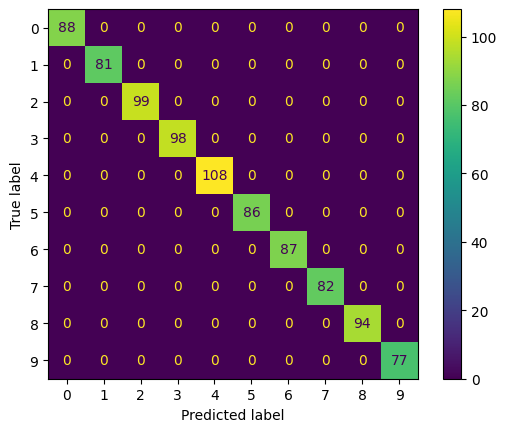

{'Accuracy': 1.0,
 'Precision': 1.0,
 'Recall': 1.0,
 'F1 Score': 1.0,
 'Classification Report': '                         precision    recall  f1-score   support\n\n   Catalyst Degradation       1.00      1.00      1.00        88\n          Chemical Leak       1.00      1.00      1.00        81\n          Contamination       1.00      1.00      1.00        99\n      Corrosion Failure       1.00      1.00      1.00        98\n      Equipment Failure       1.00      1.00      1.00       108\n          Fire Incident       1.00      1.00      1.00        86\nInstrumentation Failure       1.00      1.00      1.00        87\n         Operator Error       1.00      1.00      1.00        82\n       Pressure Failure       1.00      1.00      1.00        94\n  Temperature Excursion       1.00      1.00      1.00        77\n\n               accuracy                           1.00       900\n              macro avg       1.00      1.00      1.00       900\n           weighted avg       1.00      

In [ ]:
model_naive_bayers = MultinomialNB()
model_naive_bayers.fit(X_train_vectorise, y_train)
# perdict the train data 
y_pred_train = model_naive_bayers.predict(X_train_vectorise)
y_pred_test= model_naive_bayers.predict(X_test_vectorise)
y_pred_test_prob = model_naive_bayers.predict_proba(X_test_vectorise)[:, 1]

# create a function to show the answers 
def check_model_performance(model, y_true_test, y_pred_answer):
    accuracy = accuracy_score(y_true_test, y_pred_answer)
    precision = precision_score(y_true_test, y_pred_answer, average='weighted')
    recall = recall_score(y_true_test, y_pred_answer, average="weighted")
    f1 = f1_score(y_true_test, y_pred_answer, average="weighted")
    class_report = classification_report(y_true_test, y_pred_answer)

    # show the diagram to show the confusion matric
    confusion_matrix_display = confusion_matrix(y_true_test, y_pred_answer)
    display = ConfusionMatrixDisplay(confusion_matrix_display)
    display.plot()
    plt.show()

    return{
        "Model" : model,
        "Accuracy" : accuracy,
        "Precision" : precision,
        "Recall" : recall,
        "F1 Score" : f1,
        "Classification Report" : class_report
    }

# check the metrics of the naive bayers model 
check_model_performance("MultinomialNB", y_test, y_pred_test)

In [71]:
y_train.value_counts()

target
Instrumentation Failure    237
Temperature Excursion      222
Equipment Failure          215
Fire Incident              214
Chemical Leak              208
Corrosion Failure          206
Catalyst Degradation       205
Pressure Failure           205
Contamination              200
Operator Error             188
Name: count, dtype: int64

In [72]:
y_test.value_counts()

target
Equipment Failure          108
Contamination               99
Corrosion Failure           98
Pressure Failure            94
Catalyst Degradation        88
Instrumentation Failure     87
Fire Incident               86
Operator Error              82
Chemical Leak               81
Temperature Excursion       77
Name: count, dtype: int64

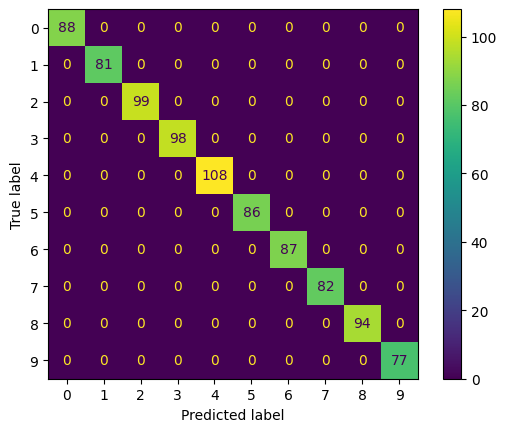

{'Accuracy': 1.0,
 'Precision': 1.0,
 'Recall': 1.0,
 'F1 Score': 1.0,
 'Classification Report': '                         precision    recall  f1-score   support\n\n   Catalyst Degradation       1.00      1.00      1.00        88\n          Chemical Leak       1.00      1.00      1.00        81\n          Contamination       1.00      1.00      1.00        99\n      Corrosion Failure       1.00      1.00      1.00        98\n      Equipment Failure       1.00      1.00      1.00       108\n          Fire Incident       1.00      1.00      1.00        86\nInstrumentation Failure       1.00      1.00      1.00        87\n         Operator Error       1.00      1.00      1.00        82\n       Pressure Failure       1.00      1.00      1.00        94\n  Temperature Excursion       1.00      1.00      1.00        77\n\n               accuracy                           1.00       900\n              macro avg       1.00      1.00      1.00       900\n           weighted avg       1.00      

In [79]:
# try with another model 
from sklearn.linear_model import LogisticRegression
model_logistic = LogisticRegression()
X_train_log, X_test_log, y_train_log, y_test_log = train_test_split(X_feature, y_target, test_size=0.3, random_state=42)

logistic_vectorise = TfidfVectorizer()
X_train_log_vectorise = logistic_vectorise.fit_transform(X_train_log)
X_test_log_vectorise = logistic_vectorise.transform(X_test_log)

model_logistic.fit(X_train_log_vectorise, y_train_log)
y_pred_log_test = model_logistic.predict(X_test_log_vectorise)

# check the perfromance of the model 
check_model_performance("Logistic Regression", y_test_log, y_pred_log_test)


In [80]:
# export the logistic regression model 
import joblib 
joblib.dump(model_logistic, "logistic_model.pkl")
joblib.dump(logistic_vectorise, "vectoriser.pkl")


['vectoriser.pkl']

### The Logistic Regression model achieved perfect performance on the held-out test set. Given that the dataset is synthetically generated from a limited number of report templates (approximately 1,300 unique descriptions across 3,000 reports), these results are likely influenced by the low linguistic variability of the data. Therefore, the reported metrics should not be interpreted as the expected performance on real industrial incident reports.